In [10]:
!pip install pandas matplotlib scikit-learn



In [11]:
import pandas as pd
df = pd.read_csv("jeruk_balance_500.csv")


In [12]:
df.shape

(500, 8)

In [13]:
df.columns

Index(['diameter', 'berat', 'tebal_kulit', 'kadar_gula', 'asal_daerah',
       'warna', 'musim_panen', 'kualitas'],
      dtype='str')

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   diameter     500 non-null    float64
 1   berat        500 non-null    float64
 2   tebal_kulit  500 non-null    float64
 3   kadar_gula   500 non-null    float64
 4   asal_daerah  500 non-null    str    
 5   warna        500 non-null    str    
 6   musim_panen  500 non-null    str    
 7   kualitas     500 non-null    str    
dtypes: float64(4), str(4)
memory usage: 31.4 KB


In [15]:
df.describe()

,diameter,berat,tebal_kulit,kadar_gula
count,500.000000,500.000000,500.000000,500.000000
mean,6.514780,150.670600,0.730460,10.020200
std,0.955277,44.637103,0.252194,1.882291
min,3.990000,74.400000,0.270000,5.800000
25%,5.747500,106.000000,0.540000,8.600000
50%,6.540000,151.600000,0.690000,10.100000
75%,7.290000,188.050000,0.882500,11.500000
max,8.730000,277.100000,1.620000,14.600000


In [16]:
df["asal_daerah"].value_counts()


asal_daerah
Jawa Tengah    194
Kalimantan     163
Jawa Barat     143
Name: count, dtype: int64

In [17]:
df["warna"].value_counts()



warna
hijau     255
kuning    148
oranye     97
Name: count, dtype: int64

In [18]:
df["musim_panen"].value_counts()


musim_panen
kemarau    251
hujan      249
Name: count, dtype: int64

In [19]:
df["kualitas"].value_counts()

kualitas
Bagus     168
Sedang    166
Jelek     166
Name: count, dtype: int64

In [20]:
df.head()


,diameter,berat,tebal_kulit,kadar_gula,asal_daerah,warna,musim_panen,kualitas
0,7.75,216.4,0.51,11.1,Kalimantan,oranye,kemarau,Bagus
1,7.43,237.9,0.43,10.6,Jawa Tengah,kuning,kemarau,Bagus
2,7.82,195.1,0.60,12.9,Jawa Barat,oranye,hujan,Bagus
3,8.26,184.9,0.49,13.9,Kalimantan,oranye,hujan,Bagus
4,7.38,182.2,0.42,10.6,Jawa Barat,oranye,kemarau,Bagus


In [21]:
df.tail()

,diameter,berat,tebal_kulit,kadar_gula,asal_daerah,warna,musim_panen,kualitas
495,6.06,106.0,0.73,7.7,Jawa Tengah,hijau,kemarau,Jelek
496,5.50,108.8,0.92,10.4,Jawa Barat,hijau,kemarau,Jelek
497,5.50,95.5,1.05,8.4,Jawa Barat,hijau,hujan,Jelek
498,7.69,221.8,0.70,13.0,Jawa Barat,oranye,hujan,Bagus
499,7.57,200.5,0.46,13.6,Kalimantan,oranye,hujan,Bagus


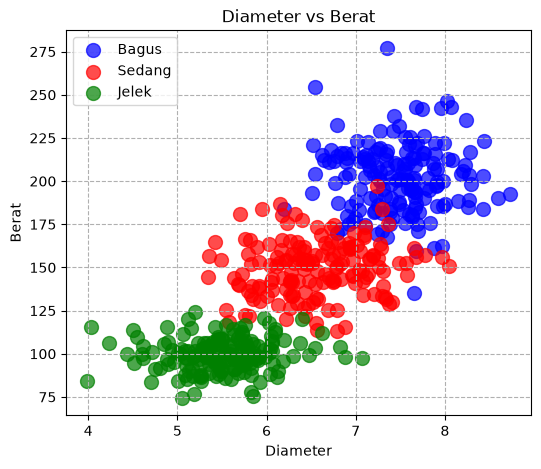

In [22]:
import matplotlib.pyplot as plt
bagus =df[df["kualitas"]=="Bagus"]
sedang =df[df["kualitas"]=="Sedang"]
jelek =df[df["kualitas"]=="Jelek"]

plt.figure(figsize=(6,5))
plt.scatter(bagus["diameter"],bagus["berat"], s=100, alpha=0.7, color="blue", label="Bagus")
plt.scatter(sedang["diameter"],sedang["berat"], s=100, alpha=0.7, color="red", label="Sedang")
plt.scatter(jelek["diameter"],jelek["berat"], s=100, alpha=0.7, color="green", label="Jelek")
plt.xlabel("Diameter")
plt.ylabel("Berat")
plt.title("Diameter vs Berat")
plt.legend()
plt.grid(True, linestyle="--", alpha=1)
plt.show()

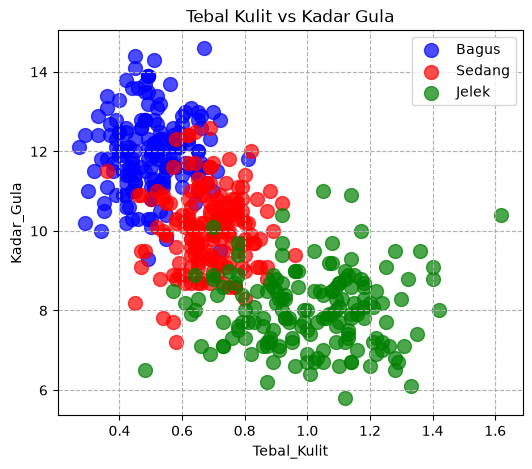

In [23]:
import matplotlib.pyplot as plt
bagus =df[df["kualitas"]=="Bagus"]
sedang =df[df["kualitas"]=="Sedang"]
jelek =df[df["kualitas"]=="Jelek"]

plt.figure(figsize=(6,5))
plt.scatter(bagus["tebal_kulit"],bagus["kadar_gula"], s=100, alpha=0.7, color="blue", label="Bagus")
plt.scatter(sedang["tebal_kulit"],sedang["kadar_gula"], s=100, alpha=0.7, color="red", label="Sedang")
plt.scatter(jelek["tebal_kulit"],jelek["kadar_gula"], s=100, alpha=0.7, color="green", label="Jelek")
plt.xlabel("Tebal_Kulit")
plt.ylabel("Kadar_Gula")
plt.title("Tebal Kulit vs Kadar Gula")
plt.legend()
plt.grid(True, linestyle="--", alpha=1)
plt.show()

In [33]:
from sklearn.linear_model import LogisticRegression #Si otak nya yang akan melakukan klasifikasi jeruk 
from sklearn.model_selection import train_test_split #untuk membagi 500 data yang akan di training sekian data dan yang akan di pengujian 
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder #fungsi StandardScaler perubahan angka agar memiliki rentang yang pendek (diliat dari standar deviasi std), fungsi OneHotEncoder untuk merubah data tulisan menjadi data angka,OrdinalEncoder untuk mengurutkan tulisan
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix #fungsi accuracy_score untuk menampilkan akurasi model berapa, fungsi classification_report melihat nilai raport keseluruhan, fungsi melihat aspek jawaban benar atau salah secara detail
from sklearn.pipeline import Pipeline #dari ColumnTransformer akan disalurkan ke Pipeline sehingga output nya memiliki 1 model saja
from sklearn.compose import ColumnTransformer #fungsinya menyatukan StandardScaler, OneHotEncoder, OrdinalEncoder prepoitioning ini menjadi satu kelas

X = df[["diameter", "berat","tebal_kulit","kadar_gula","asal_daerah","warna","musim_panen"]]
y=df["kualitas"]

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)


# 1. Kolom numerik HANYA berisi angka
numeric_columns = ["diameter", "berat", "tebal_kulit", "kadar_gula"]

# 2. Kolom kategori teks biasa (OneHotEncoder)
categorical_columns = ["asal_daerah", "musim_panen"]

# 3. Kolom ordinal (OrdinalEncoder)
ordinal_columns = ["warna"]
warna_order = ["hijau", "kuning", "oranye"]
ordinal_order = [warna_order]
preprocessing = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler (), numeric_columns),
        ("ohe", OneHotEncoder(),categorical_columns),
        ("oe", OrdinalEncoder(categories=ordinal_order), ordinal_columns)
    ]
)
model = Pipeline(
    steps=[
        ("preprocessing", preprocessing),
        ("model", LogisticRegression())
    ]
         
)
model.fit(X_train, y_train)
y_pred=model.predict(X_test)
print("Accuracy", accuracy_score(y_test,y_pred))
print("\n Classification Report:\n",classification_report(y_test, y_pred))
print("\nConfusion Matrix :\n", confusion_matrix(y_test, y_pred))

Accuracy 0.99

 Classification Report:
               precision    recall  f1-score   support

       Bagus       1.00      1.00      1.00        35
       Jelek       1.00      0.98      0.99        41
      Sedang       0.96      1.00      0.98        24

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100


Confusion Matrix :
 [[35  0  0]
 [ 0 40  1]
 [ 0  0 24]]


In [38]:
data_baru=pd.DataFrame([[7.89,200,0.35, 10, "Kalimantan", "oranye", "kemarau"]],
                       columns=["diameter", "berat","tebal_kulit","kadar_gula","asal_daerah","warna","musim_panen"])
prediksi=model.predict(data_baru)[0]
presentase=max(model.predict_proba(data_baru)[0])
print(f"Model memprediksi {prediksi} dengan tingkat keyakinan {presentase*100:.2f}%")

Model memprediksi Bagus dengan tingkat keyakinan 99.35%


In [39]:
import joblib
joblib.dump(model, "model_klasifikasi_jeruk.joblib")

['model_klasifikasi_jeruk.joblib']